<a href="https://colab.research.google.com/github/24pa1a45a0/medical-diagnosis-classification/blob/main/medical_diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/medical_diagnosis_classification.csv')

**Check column information**

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     241 non-null    object 
 1   bmi_dup         239 non-null    float64
 2   sex             246 non-null    object 
 3   age             245 non-null    float64
 4   blood_pressure  246 non-null    object 
 5   cholesterol     234 non-null    float64
 6   smoker          248 non-null    object 
 7   bmi             239 non-null    float64
 8   patient_id      243 non-null    object 
 9   disease         237 non-null    float64
dtypes: float64(5), object(5)
memory usage: 20.8+ KB


Remove Duplicate **Records**

In [3]:
df.duplicated().sum()

np.int64(15)

In [5]:
df.drop_duplicates(inplace=True)

**Remove Redundant Columns**

In [7]:
df.drop(columns=['bmi_dup'], inplace=True)

**Data standardization of blood sugar column**

In [8]:
df['blood_sugar'].unique()

array(['High', 'Lw', 'HIGH', 'NORMAL', nan, 'Normal', 'Norml', 'Low',
       'ow', 'Lo', 'LOW', 'Hig', 'Hih', 'ormal', 'Nomal', 'igh', 'Noral',
       'Norma', 'Nrmal', 'Hgh'], dtype=object)

In [9]:
df['blood_sugar'] = df['blood_sugar'].str.strip().str.lower()

df['blood_sugar'] = df['blood_sugar'].replace({
    'high': 'High',
    'hih': 'High',
    'hig': 'High',
    'igh': 'High',
    'hgh': 'High',
    'low': 'Low',
    'lw': 'Low',
    'lo': 'Low',
    'ow': 'Low',
    'normal': 'Normal',
    'nrmal': 'Normal',
    'nomal': 'Normal',
    'noral': 'Normal',
    'norml': 'Normal',
    'ormal': 'Normal'
})

**standardize the smoker column**

In [10]:
df['smoker'] = df['smoker'].str.strip().str.lower()

df['smoker'] = df['smoker'].replace({
    'yes': 'Yes',
    'ye': 'Yes',
    'ys': 'Yes',
    'es': 'Yes',
    'no': 'No',
    'n': 'No',
    'o': 'No'
})

**Standardize the gender column**

In [11]:
df['sex'] = df['sex'].str.strip().str.upper()

**handling incorrect data types**

In [12]:
import numpy as np
df['blood_pressure'] = df['blood_pressure'].replace(
    'unknown', np.nan
)
df['blood_pressure'] = pd.to_numeric(
    df['blood_pressure'], errors='coerce'
)

**data validation** :
Check minimum and maximum values

In [13]:
numeric_cols = ['age', 'bmi', 'blood_pressure', 'cholesterol']

for col in numeric_cols:
    print(col)
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print()

age
Minimum: 0.0
Maximum: 99.0

bmi
Minimum: 15.3
Maximum: 40.0

blood_pressure
Minimum: 81.6
Maximum: 13760.0

cholesterol
Minimum: 106.7
Maximum: 308.5



**Blood Pressure Validation**

In [14]:
df.loc[
    (df['blood_pressure'] < 70) |
    (df['blood_pressure'] > 250),
    'blood_pressure'
] = np.nan

**Fill categorical columns using mode**

In [16]:
categorical_cols = [
    'blood_sugar',
    'sex',
    'smoker'
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

**Fill numerical columns using median**

In [17]:
numerical_cols = [
    'age',
    'blood_pressure',
    'cholesterol',
    'bmi'
]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

**handling nulls in patient id**

In [23]:
df['patient_id'] = range(1, len(df) + 1)
df['disease'].fillna(df['disease'].mode()[0], inplace=True)

/tmp/ipykernel_585/307967248.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['disease'].fillna(df['disease'].mode()[0], inplace=True)


**data inspection after data preprocessing**

In [24]:

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# . Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# . Check data types
print("\nData Types:")
print(df.dtypes)


# . Check categorical summary
print("\nCategorical Summary:")
print(df.describe(include='object'))






Missing Values:
blood_sugar       0
sex               0
age               0
blood_pressure    0
cholesterol       0
smoker            0
bmi               0
patient_id        0
disease           0
Patient_ID        0
dtype: int64

Duplicate Records: 0

Data Types:
blood_sugar        object
sex                object
age               float64
blood_pressure    float64
cholesterol       float64
smoker             object
bmi               float64
patient_id          int64
disease           float64
Patient_ID          int64
dtype: object

Categorical Summary:
       blood_sugar  sex smoker
count          250  250    250
unique           4    2      2
top            Low    M     No
freq           100  136    210


In [38]:
df.to_csv("cleaned_data.csv", index=False)

**univariate analysis**

** Age Distribution**

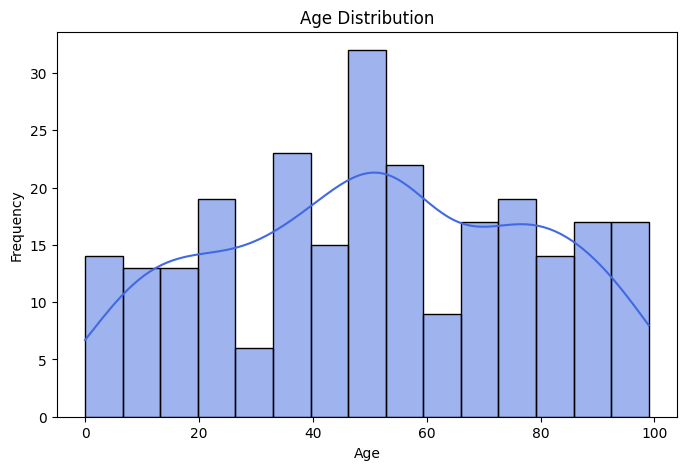

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='age', bins=15, kde=True, color='royalblue')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

**BMI Distribution**

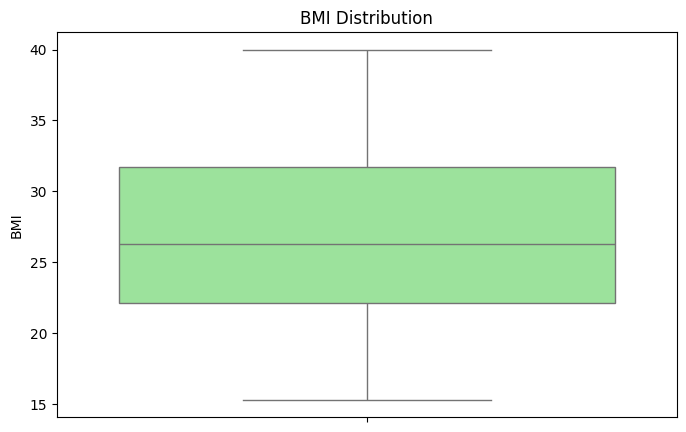

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y='bmi', color='lightgreen')
plt.title('BMI Distribution')
plt.ylabel('BMI')
plt.show()

**Cholesterol Distribution**

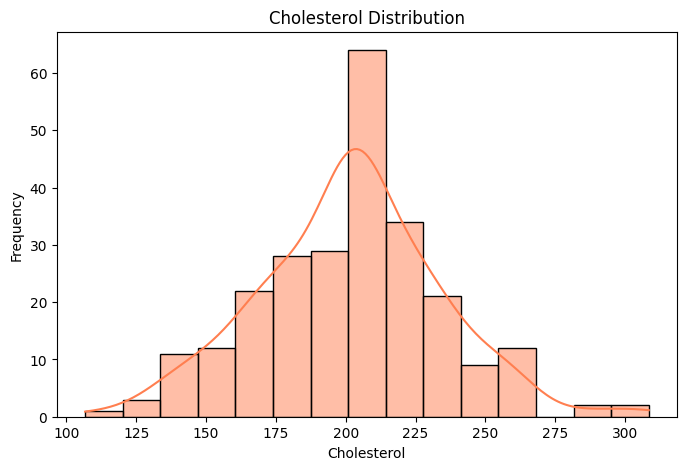

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='cholesterol', bins=15, kde=True, color='coral')
plt.title('Cholesterol Distribution')
plt.xlabel('Cholesterol')
plt.ylabel('Frequency')
plt.show()

**Gender Distribution**

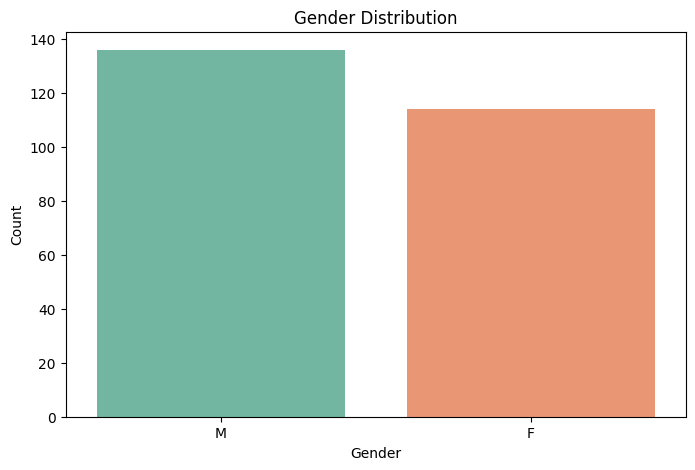

In [28]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sex', hue='sex', palette='Set2', legend=False)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

**Disease Distribution**

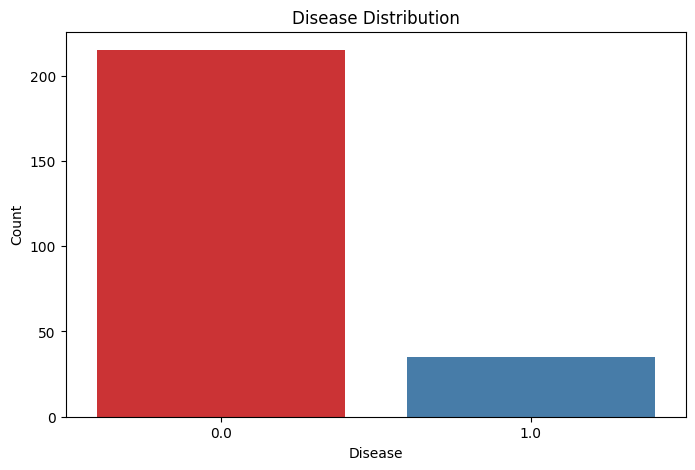

In [29]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='disease', hue='disease', palette='Set1', legend=False)
plt.title('Disease Distribution')
plt.xlabel('Disease')
plt.ylabel('Count')
plt.show()

**distribution of smokers**

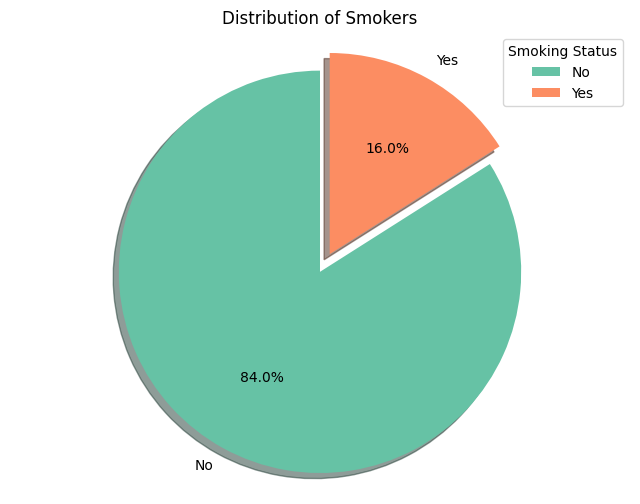

In [37]:
plt.figure(figsize=(8, 6))

smoker_counts = df['smoker'].value_counts()

plt.pie(
    smoker_counts,
    labels=smoker_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2'),
    explode=[0.05] * len(smoker_counts),
    shadow=True
)

plt.title('Distribution of Smokers')
plt.legend(smoker_counts.index, title='Smoking Status')
plt.axis('equal')
plt.show()

**bivariate analysis**

**Age vs Cholesterol**

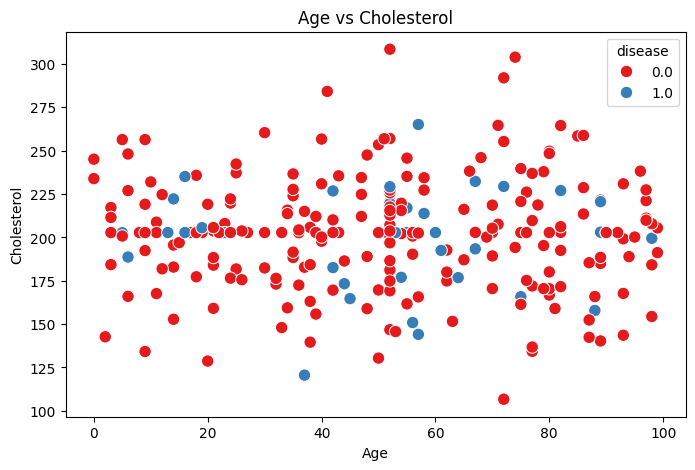

In [30]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='cholesterol', hue='disease', palette='Set1', s=80)
plt.title('Age vs Cholesterol')
plt.xlabel('Age')
plt.ylabel('Cholesterol')
plt.show()


** BMI vs Disease**

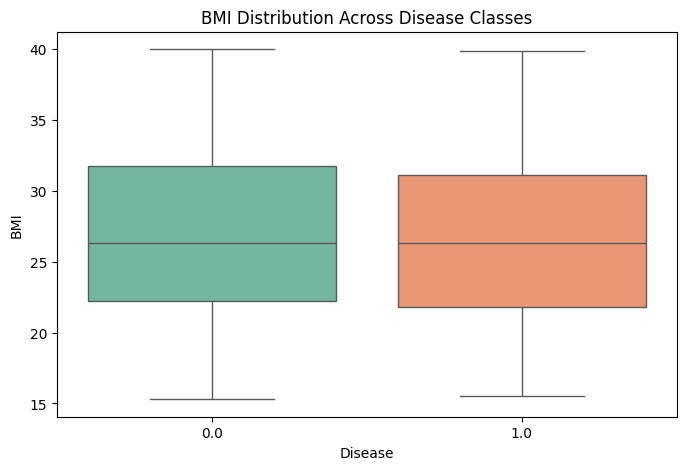

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='disease', y='bmi', hue='disease', palette='Set2', legend=False)
plt.title('BMI Distribution Across Disease Classes')
plt.xlabel('Disease')
plt.ylabel('BMI')
plt.show()


**Blood Sugar vs Disease**

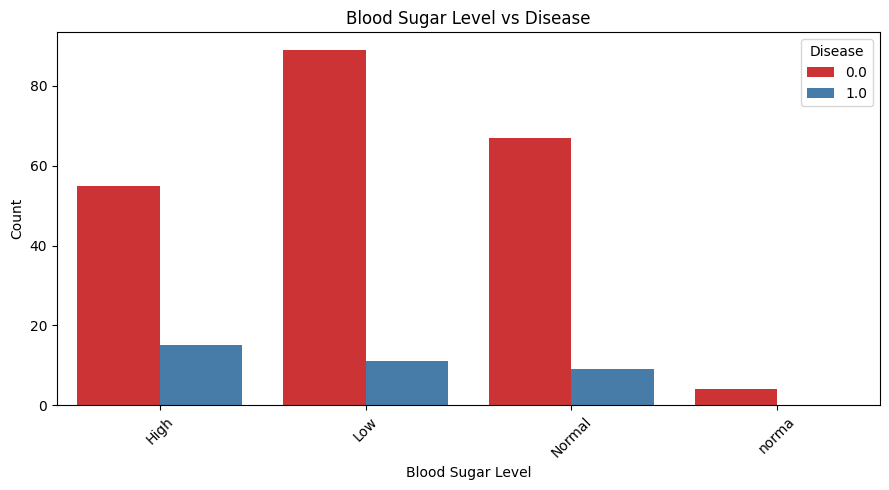

In [32]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='blood_sugar', hue='disease', palette='Set1')
plt.title('Blood Sugar Level vs Disease')
plt.xlabel('Blood Sugar Level')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Disease')
plt.tight_layout()
plt.show()

** Smoking Status vs Disease**

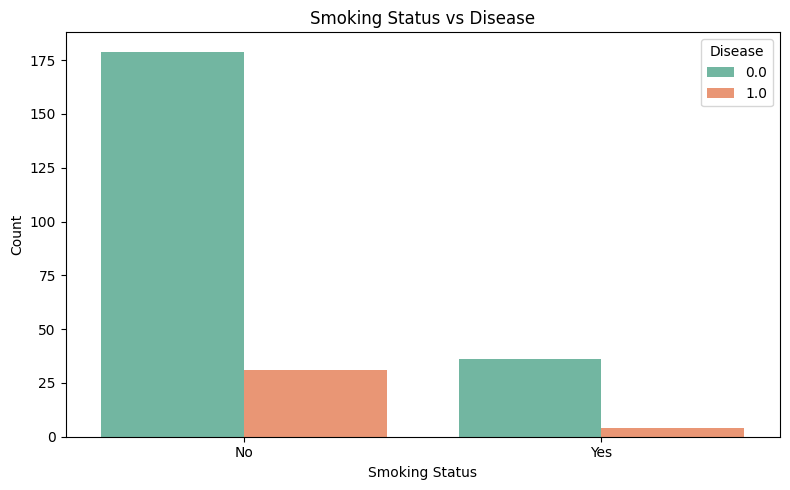

In [33]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='smoker', hue='disease', palette='Set2')
plt.title('Smoking Status vs Disease')
plt.xlabel('Smoking Status')
plt.ylabel('Count')
plt.legend(title='Disease')
plt.tight_layout()
plt.show()

**multivariate analysis**

**correlation matrix**

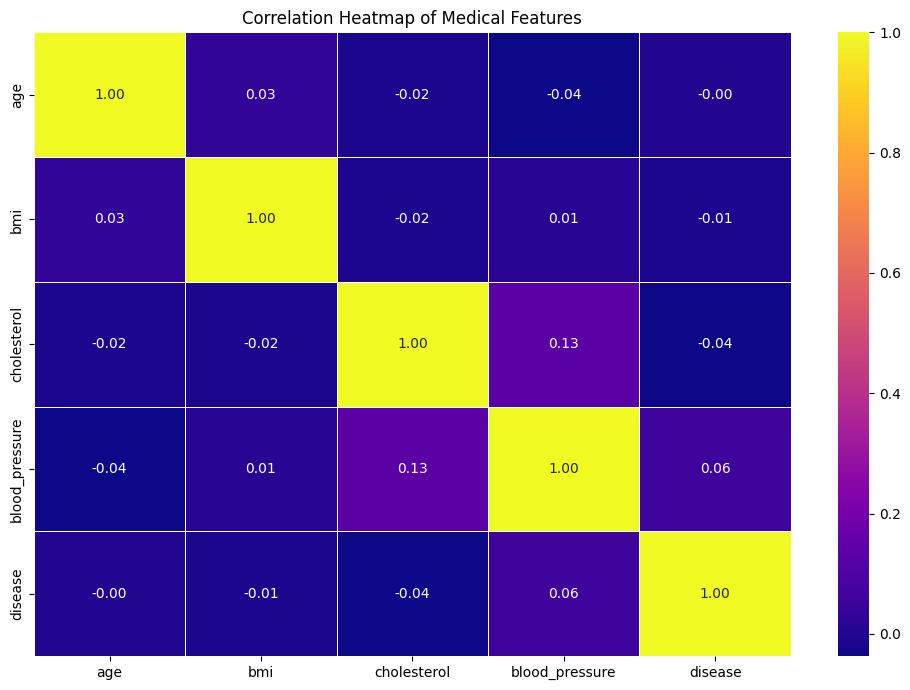

In [36]:
plt.figure(figsize=(10, 7))

numeric_df = df[['age', 'bmi', 'cholesterol', 'blood_pressure', 'disease']]

sns.heatmap(numeric_df.corr(), annot=True, cmap='plasma', fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap of Medical Features')
plt.tight_layout()
plt.show()

**pair plot**

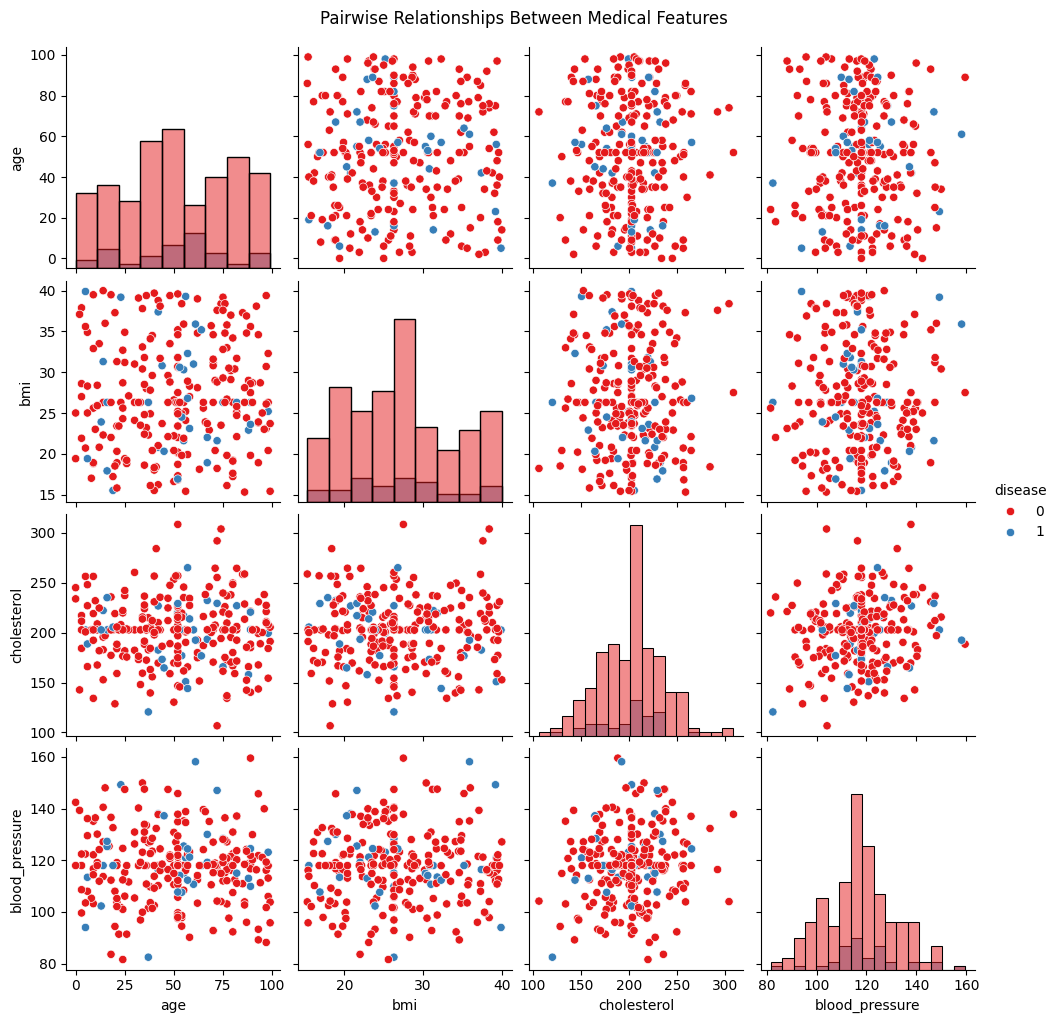

In [35]:
pair_df = df[['age', 'bmi', 'cholesterol', 'blood_pressure', 'disease']].dropna()

pair_df['disease'] = pair_df['disease'].astype(int)

sns.pairplot(
    pair_df,
    hue='disease',
    palette='Set1',
    diag_kind='hist'
)

plt.suptitle('Pairwise Relationships Between Medical Features', y=1.02)
plt.show()